In [ ]:
import joblib
import shap
import pandas as pd
from pathlib import Path

In [4]:
model = joblib.load("../models/random_forest_classifier.joblib")

In [ ]:
print(type(model))
print(model.feature_names_in_)

<class 'sklearn.ensemble._forest.RandomForestClassifier'>
['Time' 'V1' 'V2' 'V3' 'V4' 'V5' 'V6' 'V7' 'V8' 'V9' 'V10' 'V11' 'V12'
 'V13' 'V14' 'V15' 'V16' 'V17' 'V18' 'V19' 'V20' 'V21' 'V22' 'V23' 'V24'
 'V25' 'V26' 'V27' 'V28' 'Amount' 'Hours' 'LogAmount']


In [20]:

val_df = pd.read_csv("../data/processed/val.csv")


X_val = val_df.drop(columns=["Class"])


X_val = X_val[list(model.feature_names_in_)]

print(X_val.shape)

(56745, 32)


In [18]:
# Select one transaction
transaction = X_val.iloc[[0]]

# Check the model's prediction
probability = model.predict_proba(transaction)[0, 1]

print(f"Fraud probability: {probability:.4f}")

Fraud probability: 0.0008


In [6]:
explainer = shap.TreeExplainer(model)

shap_values = explainer(transaction)

print(shap_values.values.shape)

(1, 32, 2)


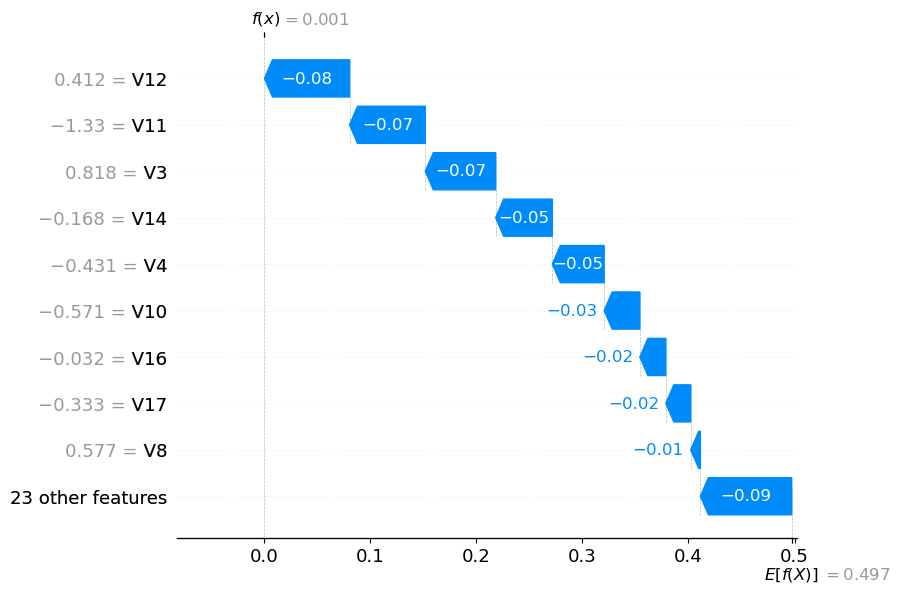

In [7]:
shap.plots.waterfall(shap_values[0, :, 1])

In [8]:
# Select an actual fraudulent transaction
fraud_indices = val_df[val_df["Class"] == 1].index

transaction = X_val.loc[[fraud_indices[0]]]

# Check model prediction
probability = model.predict_proba(transaction)[0, 1]

print(f"Fraud probability: {probability:.4f}")

Fraud probability: 0.9797


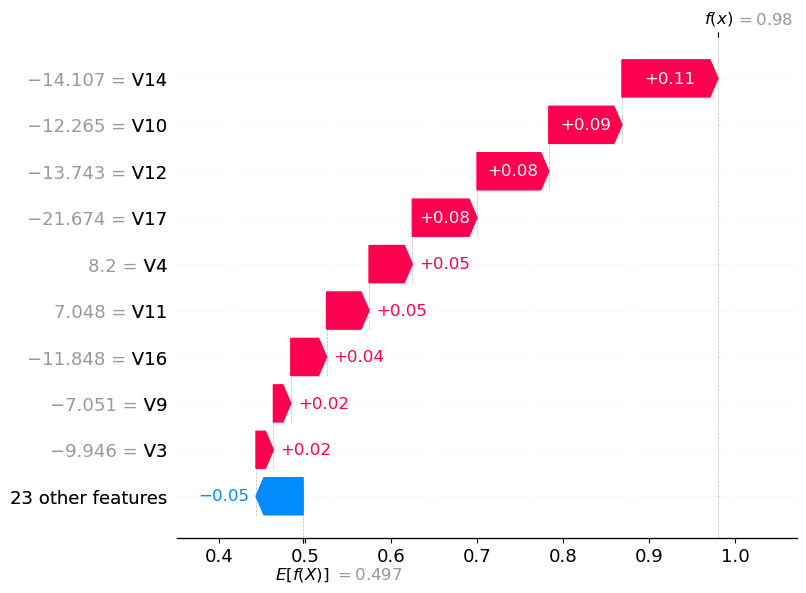

In [9]:
shap_values = explainer(transaction)

shap.plots.waterfall(shap_values[0, :, 1])